# Start

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir('/content/drive/MyDrive/data/')
os.getcwd()

import warnings
warnings.filterwarnings("ignore")

Mounted at /content/drive


In [ ]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.special import gamma
import pandas as pd
from statistics import mode
from scipy.stats import skewnorm
from tqdm import tqdm

from datetime import datetime
import pytz

## Add noise in sintetis data

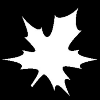

In [ ]:
#load data
filename = 'Nguyen_1.png'
T = 20
rate = 0.4
pisah = 'median'
wjk = 1

#get data
img = cv2.imread(filename,3)
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img = cv2.resize(img, (100,100))
cv2_imshow(img)

1. Rayleigh

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def rayleigh_noise(image, prob):
    # Buat salinan gambar untuk menghindari modifikasi gambar asli
    noisy_image = np.copy(image).astype(np.float32)
    rows, cols = noisy_image.shape[:2]
    num_noise_pixels = int(rows * cols * prob)
    noise_indices = np.random.choice(rows * cols, num_noise_pixels, replace=False)
    sigma = 100 # Contoh nilai, Anda bisa eksperimen dengan ini
    random_uniform = np.random.rand(num_noise_pixels)
    rayleigh_samples = sigma * np.sqrt(-2 * np.log(1 - random_uniform))
    for i, idx in enumerate(noise_indices):
            row = idx // cols
            col = idx % cols
            noisy_image[row, col] = np.clip(noisy_image[row, col] + rayleigh_samples[i], 0, 255)
    return noisy_image.astype(np.uint8)

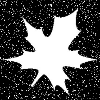

In [ ]:
img_sp_5 = rayleigh_noise(img,0.15)
cv2_imshow(img_sp_5)

2. Gaussian

In [ ]:
def gaussian_noise(image, prob):
    image = image.astype(np.float32) / 255.0  # Normalisasi ke [0, 1]
    std_dev = prob
    mean = 0
    gaussian_noise = np.random.normal(mean, std_dev, image.shape)
    noisy_img = image + gaussian_noise
    noisy_img = np.clip(noisy_img, 0, 1)
    noisy_img = (noisy_img * 255).astype(np.uint8)
    return noisy_img

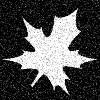

In [ ]:
img_sp_5 = gaussian_noise(img,0.15)
cv2_imshow(img_sp_5)

# cv2.imwrite('sintetis/gaussian_noise_15.png', img_sp_5)

3. Salt and Pepper

In [ ]:
import random
def sp_noise(image,prob):
    '''
    Add salt and pepper noise to image
    prob: Probability of the noise
    '''
    output = np.zeros(image.shape,np.uint8)
    thres = 1 - prob
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            rdn = random.random()
            if rdn < prob:
                output[i][j] = 0
            elif rdn > thres:
                output[i][j] = 255
            else:
                output[i][j] = image[i][j]
    return output

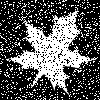

In [ ]:
img_sp_5 = sp_noise(img,0.15)
cv2_imshow(img_sp_5)

#cv2.imwrite('sintetis/sp_noise_15.png', img_sp_5)

4. Speckle

In [ ]:
def speckle_noise(image, prob):
    noisy_image = np.copy(image).astype(np.float32)
    rows, cols = noisy_image.shape[:2]
    num_noise_pixels = int(rows * cols * prob)
    noise_indices = np.random.choice(rows * cols, num_noise_pixels, replace=False)
    mean = 0.0
    variance = 0.05
    noise = np.random.normal(mean, np.sqrt(variance), num_noise_pixels)
    for i, idx in enumerate(noise_indices):
        row = idx // cols
        col = idx % cols
        noisy_image[row, col] = np.clip(noisy_image[row, col] * (1 + noise[i]), 0, 255)

    return noisy_image.astype(np.uint8)

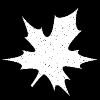

In [ ]:
img_sp_5 = speckle_noise(img,0.15)
cv2_imshow(img_sp_5)

#cv2.imwrite('sintetis/speckle_noise_15.png', img_sp_5)

saving in https://drive.google.com/drive/folders/1ZVMerXv3sc1Bw-bFAjlQlIgmo0tPA1ou

## Histogram

In [ ]:
os.listdir('sintetis/')

['rayleigh_noise_10.png',
 'rayleigh_noise_15.png',
 'gaussian_noise_05.png',
 'gaussian_noise_10.png',
 'gaussian_noise_15.png',
 'rayleigh_noise_05.png',
 'sp_noise_05.png',
 'sp_noise_10.png',
 'sp_noise_15.png',
 'speckle_noise_05.png',
 'speckle_noise_10.png',
 'speckle_noise_15.png',
 'hasil_segmentasi']

rayleigh_noise_10.png


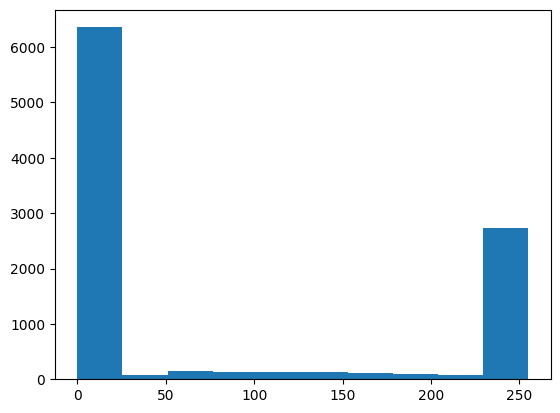

rayleigh_noise_15.png


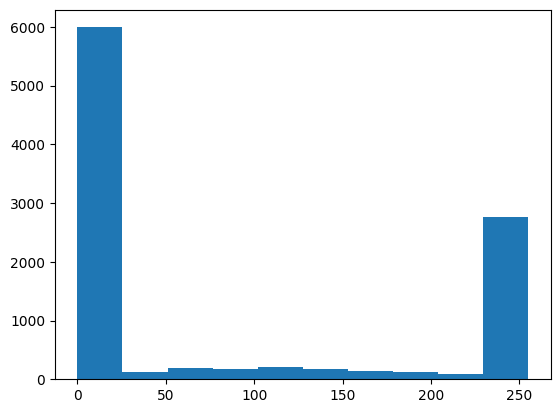

gaussian_noise_05.png


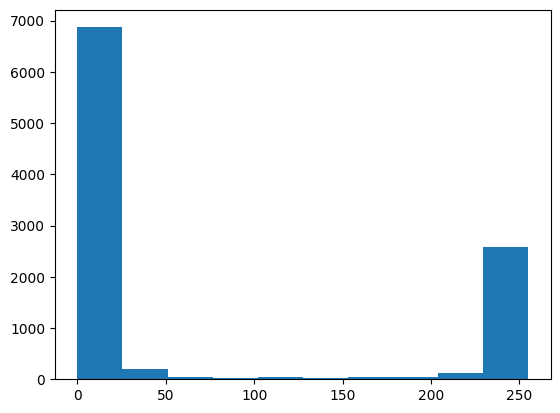

gaussian_noise_10.png


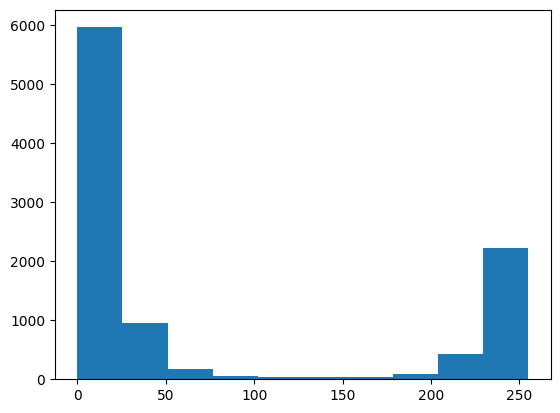

gaussian_noise_15.png


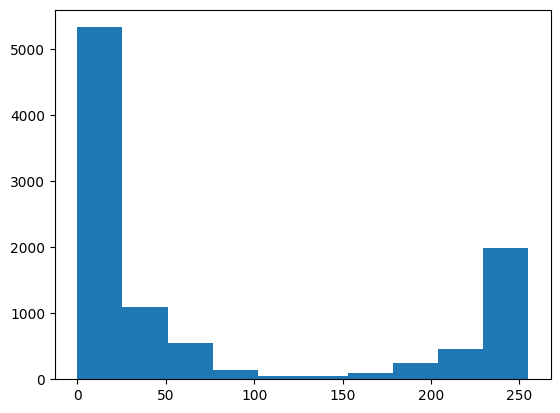

rayleigh_noise_05.png


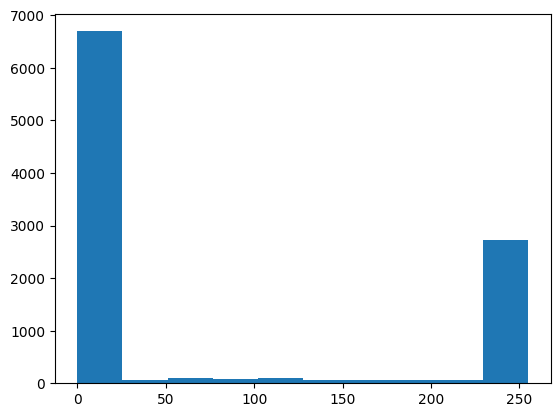

sp_noise_05.png


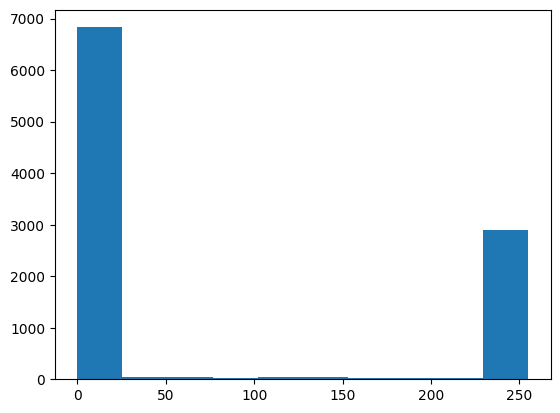

sp_noise_10.png


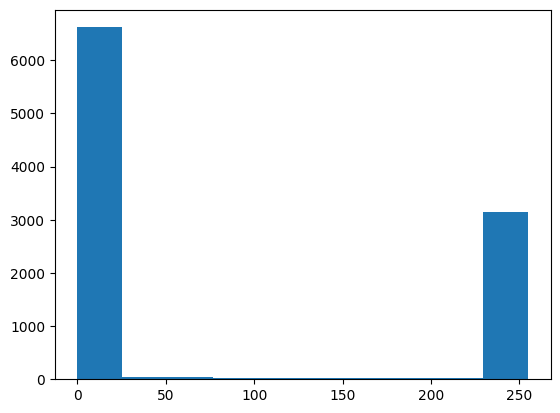

sp_noise_15.png


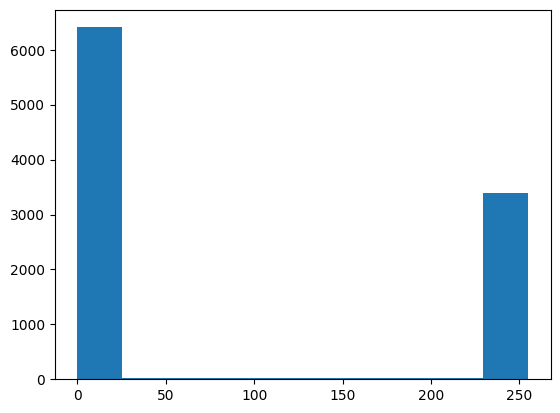

speckle_noise_05.png


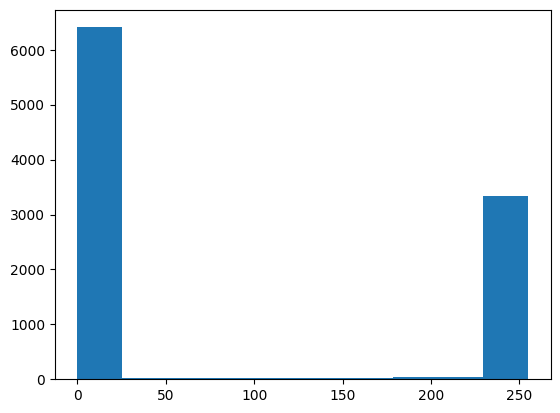

speckle_noise_10.png


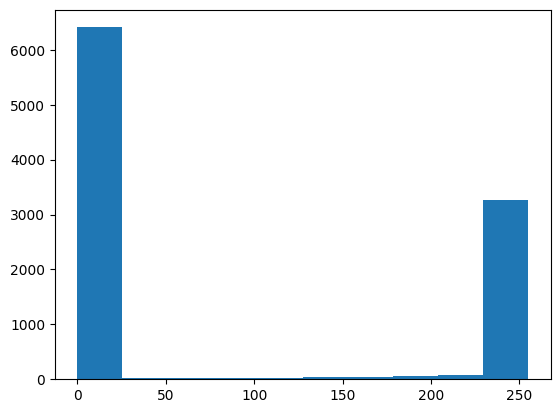

speckle_noise_15.png


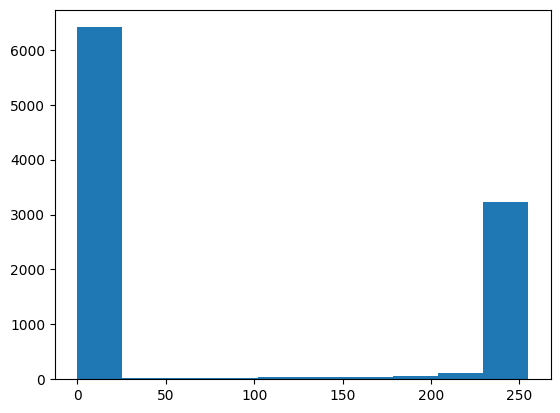

In [ ]:
for i in os.listdir('sintetis/')[:-1]:
  print(i)
  filename = 'sintetis/'+i
  img = cv2.imread(filename,0)
  #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  img = cv2.resize(img, (100,100))
  plt.hist(img.flatten())
  plt.show()

# Segmentation

## No 1. Skew Normal

In [ ]:
def pdfnorm(mu, par):
  eta = par[0]; sigma = par[1]
  return 1/(sigma*np.sqrt(2*np.pi))*np.exp(-(1/2)*((mu-eta)/sigma)**2)

def pdfinvgamma(phi, par):
  psi = par[0]; xi = par[1]
  return (xi**psi)/gamma(psi)*phi**(-(psi+1))*np.exp(-xi/phi)

def pdfgsbeta(alpha, par):
  tau = par[0]; kappa = par[1]; u = par[2]
  return gamma(2*tau)/gamma(tau**2)*(((alpha-kappa)*(u-alpha))**(tau-1)/(u-kappa)**(2*tau-1))

In [ ]:
def SN(xjk, mu, phi, alpha):
    x = xjk
    return skewnorm.pdf(x, a=alpha, loc=mu, scale=phi)

# Neo Normal Ising Model
def NNIM(xjk, mu, phi, alpha, delta):
    mu_m1 = mu[0]
    mu_p1 = mu[1]
    phi_m1 = phi[0]
    phi_p1 = phi[1]
    alpha_m1 = alpha[0]
    alpha_p1 = alpha[1]
    NNIM = SN(xjk,mu_m1, phi_m1, alpha_m1)**((1-delta)/2)*SN(xjk,mu_p1, phi_p1, alpha_p1)**((1+delta)/2)
    return NNIM

In [ ]:
def fcposterior(x, par_FC):
  # input: x, (param, xjk, delta_t, par_t, par_p, min = True)
  param = par_FC[0]; xjk = par_FC[1]; delta_t = par_FC[2]; par_t = par_FC[3]; par_p = par_FC[4]; min = par_FC[5]

  if min == True:
    mu = par_t[0][0]
    phi = par_t[1][0]
    alpha = par_t[2][0]
    d = 1

  else:
    mu = par_t[0][1]
    phi = par_t[1][1]
    alpha = par_t[2][1]
    d = 1

  if param == 'mu':
    mu = x
    eta = par_p[0]; sigma = par_p[1]

    fcp =  -0.5*((mu-eta)/sigma)**2 + np.sum(d*np.log(SN(xjk, mu, phi, alpha)))
    return fcp

  if param == 'phi':
    phi = x
    psi = par_p[0]; xi = par_p[1]

    fcp = - (psi+1)*np.log(phi)  - xi/phi + np.sum(d*np.log(SN(xjk, mu, phi, alpha)))
    return fcp

  if param == 'alpha':
    alpha = x
    u = par_p[0]; v = par_p[1]

    fcp =  -0.5*((alpha-u)/v)**2 + np.sum(d*np.log(SN(xjk, mu, phi, alpha)))
    return fcp

def bangkitmu(m, par_p, par_FC):
  c = 10**6 #Correction AR
  # par_FC = x, param, xjk, delta_t, par_t, par_p, min = True
  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    while accept == False:
      xrvs = np.random.normal(par_p[0],par_p[1],size=1)
      fx = fcposterior(xrvs, par_FC)
      Tx = np.log(stats.norm.pdf(xrvs, par_p[0], par_p[1]))
      ft = fx/(c*Tx)
      u = np.random.uniform(0, 1, size=1)
      if(np.log(u) <= ft):
        x_temp[i] = xrvs
        accept = True
  return np.mean(x_temp)

def bangkitphi(m, par_p, par_FC):
  c = 10**6 #Correction AR
  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    while accept == False:
      xrvs = stats.invgamma.rvs(par_p[0], scale=par_p[1], size = 1)[0]
      fx = fcposterior(xrvs, par_FC)
      Tx = np.log(stats.invgamma.pdf(xrvs, par_p[0], scale=par_p[1]))
      ft = fx/(c*Tx)
      u = np.random.uniform(0, 1, size=1)
      if(np.log(u) <= ft):
        x_temp[i] = xrvs
        accept = True
  return np.mean(x_temp)

def bangkitalpha(m, par_p, par_FC):
  # par_FC = x, param, xjk, delta_t, par_t, par_p, min = True
  # Acceptance Rejection
  s3 = 1

  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    while accept == False:
      xrvs = stats.norm.rvs(loc=par_p[0], scale=par_p[1], size = 1)[0]
      #if (xrvs < 1) or (xrvs > 2):
      #  continue
      #else:
      fx = fcposterior(xrvs, par_FC)
      Tx = np.log(stats.norm.pdf(xrvs, par_p[0], par_p[1]))
      ft = fx/(s3*Tx)
      u = np.random.uniform(0, 1, size=1)
      if(u <= ft):
        x_temp[i] = xrvs
        accept = True
  return np.mean(x_temp)

# rng distribution
def xrand(par_x):
  #input: (dist, par_p, size)
  dist = par_x[0]; par_p = par_x[1]; size = par_x[2]
  if dist == 'normal':
    return np.random.normal(par_p[0],par_p[1],size=size)[0]
  if dist == 'invgamma':
    return stats.invgamma.rvs(par_p[0], scale=par_p[1], size = size)[0]
  if dist == 'gamma':
    return stats.gamma.rvs(par_p[0], scale=par_p[1], size = size)[0]

In [ ]:
def sintesis(img, T, rate, pisah, wjk):
  # Try
  y = img/255.
  wjk = wjk #coupling strength (w_jk)
  P, Q = y.shape
  xjk = y.flatten()
  xjk.shape, y.shape

  # Inisialisasi
  # proses gibbs sampling
  # 1. inisialisasi parameter dari masing-masing prior pada t=0
  par_temp = np.empty((T+1,), dtype=np.ndarray) #teta_t
  #rate = 0.3 #smoothing update

  delta_t = None
  del delta_t
  delta_t = np.empty(xjk.shape)*(np.nan)
  if pisah == 'median':
    delta_t[np.where(xjk <= np.nanmedian(xjk))[0]] = -1
    delta_t[np.where(xjk > np.nanmedian(xjk))[0]] = 1
  if pisah == 'mode':
    delta_t[np.where(xjk <= mode(xjk))[0]] = -1
    delta_t[np.where(xjk > mode(xjk))[0]] = 1
  if pisah == 'mean':
    delta_t[np.where(xjk <= np.nanmean(xjk))[0]] = -1
    delta_t[np.where(xjk > np.nanmean(xjk))[0]] = 1
  #np.random.seed(0)
  #delta_t = (np.random.randint(0,2,y.flatten().shape[0])*2-1)*1.

  # delta_t[np.where(abc.flatten() <= 0)] = np.nan

  xjk_m = xjk[np.where(delta_t == -1)]
  xjk_p = xjk[np.where(delta_t == 1)]

  delta_t = np.reshape(delta_t, (Q, P))
  mu_m1_t = np.mean(xjk_m)
  mu_p1_t = np.mean(xjk_p)

  phi_m1_t = np.std(xjk_m)
  phi_p1_t = np.std(xjk_p)

  alpha_m1_t = 1
  alpha_p1_t = 1

  par_t = [[mu_m1_t,mu_p1_t],[phi_m1_t,phi_p1_t],[alpha_m1_t,alpha_p1_t]]
  par_t = np.array(par_t)

  #print(par_t)
  #print(len(xjk_m), len(xjk_p), np.mean(xjk_m), np.mean(xjk_p))
  par_temp[0] = par_t

  #print('inisialisisasi done')
  #cv2_imshow((delta_t+1)/2*255)

  # 2. pembangkitan parameter ke-t (sistem acceptance rejection)
  m = 100 #number of sampler
  it = 0
  for t in tqdm(range(T)):
  #for t in range(T):
    it += 1
    z = delta_t
    # perbarui delta

    L_m = ((1-z.flatten())/2)*np.log(SN(xjk, mu_m1_t, phi_m1_t, alpha_m1_t))
    L_p = ((1+z.flatten())/2)*np.log(SN(xjk, mu_p1_t, phi_p1_t, alpha_p1_t))

    L_m = np.reshape(L_m, (Q,P))
    L_p = np.reshape(L_p, (Q,P))

    del delta_t, xjk_m, xjk_p
    delta_t = np.reshape(np.empty(xjk.shape)*(np.nan), (Q,P))
    for ij in range(P):
      for ik in range(Q):
        pos = ik + Q*ij
        neighborhood = pos + np.array([-1,1,-Q,Q])
        boundary_idx = [ik!=0,ik!=Q-1,ij!=0,ij!=P-1]
        neighborhood = neighborhood[np.where(boundary_idx)[0]]

        jj, kk = np.unravel_index(pos, (Q,P), order='F')
        nj, nk = np.unravel_index(neighborhood, (Q,P), order='F')

        Sbar = wjk*np.nansum(z[nj,nk])
        if np.isnan(z[jj,kk]):
          delta_t[jj,kk] = np.nan
        else:
          z[jj,kk] = rate*z[jj,kk] + (1-rate)*(1/(1+np.exp(-2*Sbar + L_m[jj,kk] - L_p[jj,kk])) - 1/(1+np.exp(2*Sbar - L_m[jj,kk] + L_p[jj,kk])))
          if z[jj,kk] < 0:
            delta_t[jj,kk] = -1
          else:
            delta_t[jj,kk] = 1

    xjk_m = xjk[np.where(delta_t.flatten() == -1)]
    xjk_p = xjk[np.where(delta_t.flatten() == 1)]

    delta_t = np.reshape(delta_t, (Q, P))
    #print(t, len(xjk_m), len(xjk_p), np.mean(xjk_m), np.mean(xjk_p))

    #cv2.imshow('Image'+str(it), (delta_t+1)/2*255)
    #cv2.waitKey()
    par_temp[it] = [np.empty(2)*(np.nan),np.empty(2)*(np.nan),np.empty(2)*(np.nan)]

    # bangkitkan mu
    par_t = [par_temp[it-1][0],par_temp[it-1][1],par_temp[it-1][2]]

    par_p = [np.mean(xjk_m),np.std(xjk_m)]
    par_FC = ('mu', xjk_m, delta_t, par_t, par_p, True)
    mu_m1_t = bangkitmu(m, par_p, par_FC)

    par_p = [np.mean(xjk_p),np.std(xjk_p)]
    par_FC = ('mu', xjk_p, delta_t, par_t, par_p, False)
    mu_p1_t = bangkitmu(m, par_p, par_FC)

    par_temp[it][0] = [mu_m1_t,mu_p1_t]
    #print(t,': mu done')

    #bangkitkan phi
    par_t = [par_temp[it][0],par_temp[it-1][1],par_temp[it-1][2]]

    par_p = [2, np.std(xjk_m)]
    par_FC = ('phi', xjk_m, delta_t, par_t, par_p, True)
    phi_m1_t =  bangkitphi(m, par_p, par_FC)

    par_p = [2, np.std(xjk_p)]
    par_FC = ('phi', xjk_p, delta_t, par_t, par_p, False)
    phi_p1_t =  bangkitphi(m, par_p, par_FC)

    par_temp[it][1] = [phi_m1_t,phi_p1_t]
    #print(t,': phi done')

    # bangkitkan alpha
    par_t = [par_temp[it][0],par_temp[it][1],par_temp[it-1][2]]
    par_p = [0,np.std(xjk_m)]
    par_FC = ('alpha', xjk_m, delta_t, par_t, par_p, True)
    alpha_m1_t =  bangkitalpha(m, par_p, par_FC)

    par_p = [0,np.std(xjk_p)]
    par_FC = ('alpha', xjk_p, delta_t, par_t, par_p, False)
    alpha_p1_t =  bangkitalpha(m, par_p, par_FC)

    par_temp[it][2] = [alpha_m1_t,alpha_p1_t]
    #print(t,': alpha done')

    #if t%50 == 0:
    #  cv2_imshow((delta_t+1)/2*255)

  return par_temp, delta_t

rayleigh_noise_10.png


100%|██████████| 200/200 [03:00<00:00,  1.11it/s]


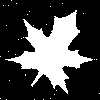

rayleigh_noise_15.png


100%|██████████| 200/200 [02:58<00:00,  1.12it/s]


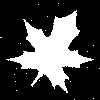

gaussian_noise_05.png


100%|██████████| 200/200 [03:02<00:00,  1.09it/s]


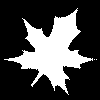

gaussian_noise_10.png


100%|██████████| 200/200 [02:57<00:00,  1.13it/s]


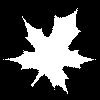

gaussian_noise_15.png


100%|██████████| 200/200 [02:55<00:00,  1.14it/s]


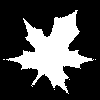

rayleigh_noise_05.png


100%|██████████| 200/200 [02:54<00:00,  1.15it/s]


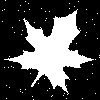

sp_noise_05.png


100%|██████████| 200/200 [02:59<00:00,  1.12it/s]


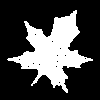

sp_noise_10.png


100%|██████████| 200/200 [03:29<00:00,  1.05s/it]


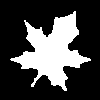

sp_noise_15.png


100%|██████████| 200/200 [03:07<00:00,  1.06it/s]


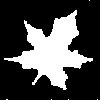

speckle_noise_05.png


100%|██████████| 200/200 [03:08<00:00,  1.06it/s]


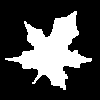

speckle_noise_10.png


100%|██████████| 200/200 [03:05<00:00,  1.08it/s]


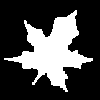

speckle_noise_15.png


100%|██████████| 200/200 [03:07<00:00,  1.07it/s]


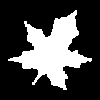

hasil_segmentasi


error: OpenCV(4.13.0) /io/opencv/modules/imgproc/src/resize.cpp:4208: error: (-215:Assertion failed) !ssize.empty() in function 'resize'


In [ ]:
#load data
T = 200
rate = 0.4
pisah = 'mean'
wjk = 1

for i in os.listdir('sintetis/'):
  print(i)
  filename = 'sintetis/'+i
  img = cv2.imread(filename,0)
  #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  img = cv2.resize(img, (100,100))
  #get data
  par_temp, delta_hasil = sintesis(img, T=T, rate=rate, pisah = pisah, wjk=wjk)
  cv2_imshow((delta_hasil+1)/2*255)
  cv2.imwrite('sintetis/hasil_segmentasi/'+'SN_'+i, (delta_hasil+1)/2*255)

## No 2. FSSN

In [ ]:
def FSSN(xjk, mu, phi, alpha):
  a = 2/(alpha+1/alpha)
  b = 1/(phi*np.sqrt(2*np.pi**2))
  c = np.exp(-0.5*((xjk-mu)/phi)**2)
  d = (1/alpha**2) if xjk.any() > mu else (alpha**2)
  return a*b*c*d

In [ ]:
def pdfnorm(mu, par):
    eta = par[0]; sigma = par[1]
    return 1/(sigma*np.sqrt(2*np.pi))*np.exp(-(1/2)*((mu-eta)/sigma)**2)

def pdfinvgamma(phi, par):
  psi = par[0]; xi = par[1]
  return (xi**psi)/gamma(psi)*phi**(-(psi+1))*np.exp(-xi/phi)


def pdfgsbeta(alpha, par):
  tau = par[0]; kappa = par[1]; u = par[2]
  return gamma(2*tau)/gamma(tau**2)*(((alpha-kappa)*(u-alpha))**(tau-1)/(u-kappa)**(2*tau-1))

In [ ]:
def fcposterior(x, par_FC):
  # input: x, (param, xjk, delta_t, par_t, par_p, min = True)
  param = par_FC[0]; xjk = par_FC[1]; delta_t = par_FC[2]; par_t = par_FC[3]; par_p = par_FC[4]; min = par_FC[5]

  if min == True:
    mu = par_t[0][0]
    phi = par_t[1][0]
    alpha = par_t[2][0]
    d = 1
  else:
    mu = par_t[0][1]
    phi = par_t[1][1]
    alpha = par_t[2][1]
    d = 1

  if param == 'mu':
    mu = x
    eta = par_p[0]; sigma = par_p[1]

    fcp = -0.5*((mu-eta)/sigma)**2 + np.sum(d*(-0.5*((xjk-mu)/phi)**2))
    return fcp

  if param == 'phi':
    phi = x
    psi = par_p[0]; xi = par_p[1]

    fcp = - (psi+1)*np.log(phi)  - xi/phi + np.sum(d*(-np.log(phi)-0.5*((xjk-mu)/phi)**2))
    return fcp

  if param == 'alpha':
    alpha = x
    u = par_p[0]; v = par_p[1]

    fcp =  (u-1)*np.log(u) - v*alpha + np.sum(d*(np.log(alpha) - np.log(alpha**2+1)) + (np.log((1/alpha**2)) if xjk.any() > mu else np.log(alpha**2)))
    return fcp

def bangkitmu(m, par_p, par_FC):
  c = 10**6 #Correction AR
  # par_FC = x, param, xjk, delta_t, par_t, par_p, min = True
  #Acceptance Rejection
  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    #print(i)
    while accept == False:
      xrvs = np.random.normal(par_p[0],par_p[1],size=1)
      fx = fcposterior(xrvs, par_FC)
      Tx = np.log(stats.norm.pdf(xrvs, par_p[0], par_p[1]))
      ft = fx/(c*Tx)
      u = np.random.uniform(0, 1, size=1)
      if(np.log(u) <= ft):
        x_temp[i] = xrvs
        accept = True
  return np.mean(x_temp)

def bangkitphi(m, par_p, par_FC):
  c = 10**6 #Correction AR
  #Acceptance Rejection
  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    while accept == False:
      xrvs = stats.invgamma.rvs(par_p[0], scale=par_p[1], size = 1)[0]
      #xrvs = stats.gamma.rvs(par_p[0], scale=par_p[1], size = 1)
      fx = fcposterior(xrvs, par_FC)
      Tx = np.log(stats.invgamma.pdf(xrvs, par_p[0], scale=par_p[1]))
      ft = fx/(c*Tx)
      u = np.random.uniform(0, 1, size=1)
      #print(xrvs, fx, Tx, ft, np.log(u))
      if(np.log(u) <= ft):
        x_temp[i] = xrvs
        accept = True
  return np.mean(x_temp)

def bangkitalpha(m, par_p, par_FC):
  # par_FC = x, param, xjk, delta_t, par_t, par_p, min = True
  # Acceptance Rejection
  s3 = 1

  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    #print(i)
    while accept == False:
      xrvs = stats.gamma.rvs(par_p[0], scale=par_p[1], size = 1)[0] + 1
      if (xrvs < 1) or (xrvs > 2):
        continue
      else:
        fx = fcposterior(xrvs, par_FC)
        Tx = np.log(stats.gamma.pdf(xrvs, par_p[0], scale=par_p[1]))
        ft = fx/(s3*Tx)
        u = np.random.uniform(0, 1, size=1)
        #print(xrvs, fx, Tx, ft, u)
        if(u <= ft):
          x_temp[i] = xrvs
          accept = True
  return np.mean(x_temp)

# rng distribution
def xrand(par_x):
  #input: (dist, par_p, size)
  dist = par_x[0]; par_p = par_x[1]; size = par_x[2]
  if dist == 'normal':
    return np.random.normal(par_p[0],par_p[1],size=size)[0]
  if dist == 'invgamma':
    return stats.invgamma.rvs(par_p[0], scale=par_p[1], size = size)[0]
  if dist == 'gamma':
    return stats.gamma.rvs(par_p[0], scale=par_p[1], size = size)[0]

In [ ]:
def sintetis_FSSN(img, T, rate, pisah, wjk):
  # Try
  y = img/255.
  #y = 2*y-1
  wjk = wjk #coupling strength (w_jk)
  P, Q = y.shape
  xjk = y.flatten()

  #plt.hist(xjk, bins=50)
  #plt.show()

  #y = xjk.reshape((Q,P))
  xjk.shape, y.shape

  # Inisialisasi
  # proses gibbs sampling
  # 1. inisialisasi parameter dari masing-masing prior pada t=0
  par_temp = np.empty((T+1,), dtype=np.ndarray) #teta_t
  #rate = 0.3 #smoothing update

  delta_t = None
  del delta_t
  delta_t = np.empty(xjk.shape)*(np.nan)
  if pisah == 'median':
    delta_t[np.where(xjk <= np.nanmedian(xjk))[0]] = -1
    delta_t[np.where(xjk > np.nanmedian(xjk))[0]] = 1
  if pisah == 'mode':
    delta_t[np.where(xjk <= mode(xjk))[0]] = -1
    delta_t[np.where(xjk > mode(xjk))[0]] = 1
  if pisah == 'mean':
    delta_t[np.where(xjk <= np.nanmean(xjk))[0]] = -1
    delta_t[np.where(xjk > np.nanmean(xjk))[0]] = 1

  #np.random.seed(0)
  #delta_t = (np.random.randint(0,2,y.flatten().shape[0])*2-1)*1.

  # delta_t[np.where(abc.flatten() <= 0)] = np.nan

  xjk_m = xjk[np.where(delta_t == -1)]
  xjk_p = xjk[np.where(delta_t == 1)]

  delta_t = np.reshape(delta_t, (Q, P))
  mu_m1_t = np.mean(xjk_m)
  mu_p1_t = np.mean(xjk_p)

  phi_m1_t = np.std(xjk_m)
  phi_p1_t = np.std(xjk_p)

  alpha_m1_t = 1
  alpha_p1_t = 1

  par_t = [[mu_m1_t,mu_p1_t],[phi_m1_t,phi_p1_t],[alpha_m1_t,alpha_p1_t]]
  par_t = np.array(par_t)

  #print(par_t)
  #print(len(xjk_m), len(xjk_p), np.mean(xjk_m), np.mean(xjk_p))
  par_temp[0] = par_t

  #print('inisialisisasi done')
  #cv2_imshow((delta_t+1)/2*255)

  # 2. pembangkitan parameter ke-t (sistem acceptance rejection)
  m = 100 #number of sampler
  it = 0
  for t in tqdm(range(T)):
    it += 1
    z = delta_t
    # perbarui delta
    L_m = ((1-z.flatten())/2)*np.log(FSSN(xjk, mu_m1_t, phi_m1_t, alpha_m1_t))
    L_p = ((1+z.flatten())/2)*np.log(FSSN(xjk, mu_p1_t, phi_p1_t, alpha_p1_t))

    L_m = np.reshape(L_m, (Q,P))
    L_p = np.reshape(L_p, (Q,P))

    del delta_t, xjk_m, xjk_p
    delta_t = np.reshape(np.empty(xjk.shape)*(np.nan), (Q,P))
    for ij in range(P):
      for ik in range(Q):
        pos = ik + Q*ij
        neighborhood = pos + np.array([-1,1,-Q,Q])
        boundary_idx = [ik!=0,ik!=Q-1,ij!=0,ij!=P-1]
        neighborhood = neighborhood[np.where(boundary_idx)[0]]

        jj, kk = np.unravel_index(pos, (Q,P), order='F')
        nj, nk = np.unravel_index(neighborhood, (Q,P), order='F')

        Sbar = wjk*np.nansum(z[nj,nk])
        if np.isnan(z[jj,kk]):
          delta_t[jj,kk] = np.nan
        else:
          z[jj,kk] = rate*z[jj,kk] + (1-rate)*(1/(1+np.exp(-2*Sbar + L_m[jj,kk] - L_p[jj,kk])) - 1/(1+np.exp(2*Sbar - L_m[jj,kk] + L_p[jj,kk])))
          if z[jj,kk] < 0:
            delta_t[jj,kk] = -1
          else:
            delta_t[jj,kk] = 1

    xjk_m = xjk[np.where(delta_t.flatten() == -1)]
    xjk_p = xjk[np.where(delta_t.flatten() == 1)]

    delta_t = np.reshape(delta_t, (Q, P))
    #print(t, len(xjk_m), len(xjk_p), np.mean(xjk_m), np.mean(xjk_p))

    #cv2.imshow('Image'+str(it), (delta_t+1)/2*255)
    #cv2.waitKey()
    par_temp[it] = [np.empty(2)*(np.nan),np.empty(2)*(np.nan),np.empty(2)*(np.nan)]

    # bangkitkan mu
    par_t = [par_temp[it-1][0],par_temp[it-1][1],par_temp[it-1][2]]

    par_p = [np.mean(xjk_m),np.std(xjk_m)]
    par_FC = ('mu', xjk_m, delta_t, par_t, par_p, True)
    mu_m1_t = bangkitmu(m, par_p, par_FC)

    par_p = [np.mean(xjk_p),np.std(xjk_p)]
    par_FC = ('mu', xjk_p, delta_t, par_t, par_p, False)
    mu_p1_t = bangkitmu(m, par_p, par_FC)

    par_temp[it][0] = [mu_m1_t,mu_p1_t]
    #print(t,': mu done')

    #bangkitkan phi
    par_t = [par_temp[it][0],par_temp[it-1][1],par_temp[it-1][2]]

    par_p = [2, np.std(xjk_m)]
    par_FC = ('phi', xjk_m, delta_t, par_t, par_p, True)
    phi_m1_t =  bangkitphi(m, par_p, par_FC)

    par_p = [2, np.std(xjk_p)]
    par_FC = ('phi', xjk_p, delta_t, par_t, par_p, False)
    phi_p1_t =  bangkitphi(m, par_p, par_FC)

    par_temp[it][1] = [phi_m1_t,phi_p1_t]
    #print(t,': phi done')

    # bangkitkan alpha
    par_t = [par_temp[it][0],par_temp[it][1],par_temp[it-1][2]]
    par_p = [1, np.std(xjk_m)/np.sqrt(1)]
    par_FC = ('alpha', xjk_m, delta_t, par_t, par_p, True)
    alpha_m1_t =  bangkitalpha(m, par_p, par_FC)

    par_p = [1, np.std(xjk_p)/np.sqrt(1)]
    par_FC = ('alpha', xjk_p, delta_t, par_t, par_p, False)
    alpha_p1_t =  bangkitalpha(m, par_p, par_FC)

    par_temp[it][2] = [alpha_m1_t,alpha_p1_t]
    #print(t,': alpha done')

    # if t%50 == 0:
    #   cv2_imshow((delta_t+1)/2*255)

  return par_temp, delta_t

rayleigh_noise_10.png


100%|██████████| 200/200 [03:05<00:00,  1.08it/s]


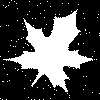

rayleigh_noise_15.png


100%|██████████| 200/200 [03:02<00:00,  1.10it/s]


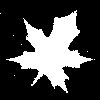

gaussian_noise_05.png


100%|██████████| 200/200 [03:48<00:00,  1.14s/it]


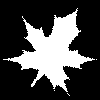

gaussian_noise_10.png


100%|██████████| 200/200 [03:26<00:00,  1.03s/it]


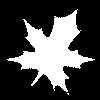

gaussian_noise_15.png


100%|██████████| 200/200 [03:07<00:00,  1.06it/s]


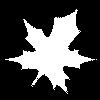

rayleigh_noise_05.png


100%|██████████| 200/200 [03:06<00:00,  1.07it/s]


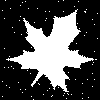

sp_noise_05.png


100%|██████████| 200/200 [02:40<00:00,  1.25it/s]


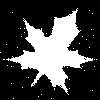

sp_noise_10.png


100%|██████████| 200/200 [02:08<00:00,  1.56it/s]


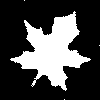

sp_noise_15.png


100%|██████████| 200/200 [01:54<00:00,  1.74it/s]


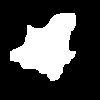

speckle_noise_05.png


100%|██████████| 200/200 [01:54<00:00,  1.75it/s]


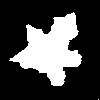

speckle_noise_10.png


100%|██████████| 200/200 [01:53<00:00,  1.76it/s]


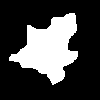

speckle_noise_15.png


100%|██████████| 200/200 [01:55<00:00,  1.74it/s]


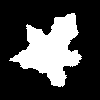

hasil_segmentasi


error: OpenCV(4.12.0) /io/opencv/modules/imgproc/src/resize.cpp:4208: error: (-215:Assertion failed) !ssize.empty() in function 'resize'


In [ ]:
#load data
T = 200
rate = 0.4
pisah = 'mean'
wjk = 1

for i in os.listdir('sintetis/'):
  print(i)
  filename = 'sintetis/'+i
  img = cv2.imread(filename,0)
  #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  img = cv2.resize(img, (100,100))
  #get data
  par_temp, delta_hasil = sintetis_FSSN(img, T=T, rate=rate, pisah = pisah, wjk=wjk)
  cv2_imshow((delta_hasil+1)/2*255)
  cv2.imwrite('sintetis/hasil_segmentasi/'+'FSSN_'+i, (delta_hasil+1)/2*255)

## No 3. Normal Ising

In [ ]:
def pdfnorm(mu, par):
  eta = par[0]; sigma = par[1]
  return 1/(sigma*np.sqrt(2*np.pi))*np.exp(-(1/2)*((mu-eta)/sigma)**2)

def pdfinvgamma(phi, par):
  psi = par[0]; xi = par[1]
  return (xi**psi)/gamma(psi)*phi**(-(psi+1))*np.exp(-xi/phi)

def pdfgsbeta(alpha, par):
  tau = par[0]; kappa = par[1]; u = par[2]
  return gamma(2*tau)/gamma(tau**2)*(((alpha-kappa)*(u-alpha))**(tau-1)/(u-kappa)**(2*tau-1))

In [ ]:
from scipy.stats import norm
def Norm(xjk, mu, phi):
    x = xjk
    return norm.pdf(x, loc=mu, scale=phi)

# Neo Normal Ising Model
def NNIM(xjk, mu, phi, alpha, delta):
    mu_m1 = mu[0]
    mu_p1 = mu[1]
    phi_m1 = phi[0]
    phi_p1 = phi[1]
    alpha_m1 = alpha[0]
    alpha_p1 = alpha[1]
    NNIM = Norm(xjk,mu_m1, phi_m1, alpha_m1)**((1-delta)/2)*Norm(xjk,mu_p1, phi_p1, alpha_p1)**((1+delta)/2)
    return NNIM

In [ ]:
def fcposterior(x, par_FC):
  # input: x, (param, xjk, delta_t, par_t, par_p, min = True)
  param = par_FC[0]; xjk = par_FC[1]; delta_t = par_FC[2]; par_t = par_FC[3]; par_p = par_FC[4]; min = par_FC[5]

  if min == True:
    mu = par_t[0][0]
    phi = par_t[1][0]
    # alpha = par_t[2][0]
    d = 1

  else:
    mu = par_t[0][1]
    phi = par_t[1][1]
    # alpha = par_t[2][1]
    d = 1

  if param == 'mu':
    mu = x
    eta = par_p[0]; sigma = par_p[1]

    fcp =  -0.5*((mu-eta)/sigma)**2 + np.sum(d*np.log(Norm(xjk, mu, phi)))
    return fcp

  if param == 'phi':
    phi = x
    psi = par_p[0]; xi = par_p[1]

    fcp = - (psi+1)*np.log(phi)  - xi/phi + np.sum(d*np.log(Norm(xjk, mu, phi)))
    return fcp

  # if param == 'alpha':
  #   alpha = x
  #   u = par_p[0]; v = par_p[1]

  #   fcp =  -0.5*((alpha-u)/v)**2 + np.sum(d*np.log(SN(xjk, mu, phi, alpha)))
  #   return fcp

def bangkitmu(m, par_p, par_FC):
  c = 10**6 #Correction AR
  # par_FC = x, param, xjk, delta_t, par_t, par_p, min = True
  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    while accept == False:
      xrvs = np.random.normal(par_p[0],par_p[1],size=1)
      fx = fcposterior(xrvs, par_FC)
      Tx = np.log(stats.norm.pdf(xrvs, par_p[0], par_p[1]))
      ft = fx/(c*Tx)
      u = np.random.uniform(0, 1, size=1)
      if(np.log(u) <= ft):
        x_temp[i] = xrvs
        accept = True
  return np.mean(x_temp)

def bangkitphi(m, par_p, par_FC):
  c = 10**6 #Correction AR
  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    while accept == False:
      xrvs = stats.invgamma.rvs(par_p[0], scale=par_p[1], size = 1)[0]
      fx = fcposterior(xrvs, par_FC)
      Tx = np.log(stats.invgamma.pdf(xrvs, par_p[0], scale=par_p[1]))
      ft = fx/(c*Tx)
      u = np.random.uniform(0, 1, size=1)
      if(np.log(u) <= ft):
        x_temp[i] = xrvs
        accept = True
  return np.mean(x_temp)

# def bangkitalpha(m, par_p, par_FC):
#   # par_FC = x, param, xjk, delta_t, par_t, par_p, min = True
#   # Acceptance Rejection
#   s3 = 1

#   x_temp = np.empty(m)*(np.nan)
#   for i in range(m):
#     accept = False
#     while accept == False:
#       xrvs = stats.norm.rvs(loc=par_p[0], scale=par_p[1], size = 1)[0]
#       #if (xrvs < 1) or (xrvs > 2):
#       #  continue
#       #else:
#       fx = fcposterior(xrvs, par_FC)
#       Tx = np.log(stats.norm.pdf(xrvs, par_p[0], par_p[1]))
#       ft = fx/(s3*Tx)
#       u = np.random.uniform(0, 1, size=1)
#       if(u <= ft):
#         x_temp[i] = xrvs
#         accept = True
#   return np.mean(x_temp)

# rng distribution
def xrand(par_x):
  #input: (dist, par_p, size)
  dist = par_x[0]; par_p = par_x[1]; size = par_x[2]
  if dist == 'normal':
    return np.random.normal(par_p[0],par_p[1],size=size)[0]
  if dist == 'invgamma':
    return stats.invgamma.rvs(par_p[0], scale=par_p[1], size = size)[0]
  if dist == 'gamma':
    return stats.gamma.rvs(par_p[0], scale=par_p[1], size = size)[0]

In [ ]:
def sintetis_Normal(img, T, rate, pisah, wjk):
  # Try
  y = img/255.
  #y = 2*y-1
  wjk = wjk #coupling strength (w_jk)
  P, Q = y.shape
  xjk = y.flatten()

  # plt.hist(xjk, bins=50)
  # plt.show()

  #y = xjk.reshape((Q,P))
  xjk.shape, y.shape

  # Inisialisasi
  # proses gibbs sampling
  # 1. inisialisasi parameter dari masing-masing prior pada t=0
  par_temp = np.empty((T+1,), dtype=np.ndarray) #teta_t
  #rate = 0.3 #smoothing update

  delta_t = None
  del delta_t
  delta_t = np.empty(xjk.shape)*(np.nan)
  if pisah == 'median':
    delta_t[np.where(xjk <= np.nanmedian(xjk))[0]] = -1
    delta_t[np.where(xjk > np.nanmedian(xjk))[0]] = 1
  if pisah == 'mode':
    delta_t[np.where(xjk <= mode(xjk))[0]] = -1
    delta_t[np.where(xjk > mode(xjk))[0]] = 1
  if pisah == 'mean':
    delta_t[np.where(xjk <= np.nanmean(xjk))[0]] = -1
    delta_t[np.where(xjk > np.nanmean(xjk))[0]] = 1
  #np.random.seed(0)
  #delta_t = (np.random.randint(0,2,y.flatten().shape[0])*2-1)*1.

  xjk_m = xjk[np.where(delta_t == -1)]
  xjk_p = xjk[np.where(delta_t == 1)]

  delta_t = np.reshape(delta_t, (Q, P))
  mu_m1_t = np.mean(xjk_m)
  mu_p1_t = np.mean(xjk_p)

  phi_m1_t = np.std(xjk_m)
  phi_p1_t = np.std(xjk_p)

  par_t = [[mu_m1_t,mu_p1_t],[phi_m1_t,phi_p1_t]]
  par_t = np.array(par_t)

  #print(par_t)
  # print(len(xjk_m), len(xjk_p), np.mean(xjk_m), np.mean(xjk_p))
  par_temp[0] = par_t

  #print('inisialisisasi done')
  #cv2_imshow((delta_t+1)/2*255)

  # 2. pembangkitan parameter ke-t (sistem acceptance rejection)
  m = 100 #number of sampler
  it = 0
  for t in tqdm(range(T)):
    it += 1
    z = delta_t
    # perbarui delta

    L_m = ((1-z.flatten())/2)*np.log(Norm(xjk, mu_m1_t, phi_m1_t))
    L_p = ((1+z.flatten())/2)*np.log(Norm(xjk, mu_p1_t, phi_p1_t))

    L_m = np.reshape(L_m, (Q,P))
    L_p = np.reshape(L_p, (Q,P))

    del delta_t, xjk_m, xjk_p
    delta_t = np.reshape(np.empty(xjk.shape)*(np.nan), (Q,P))
    for ij in range(P):
      for ik in range(Q):
        pos = ik + Q*ij
        neighborhood = pos + np.array([-1,1,-Q,Q])
        boundary_idx = [ik!=0,ik!=Q-1,ij!=0,ij!=P-1]
        neighborhood = neighborhood[np.where(boundary_idx)[0]]

        jj, kk = np.unravel_index(pos, (Q,P), order='F')
        nj, nk = np.unravel_index(neighborhood, (Q,P), order='F')

        Sbar = wjk*np.nansum(z[nj,nk])
        if np.isnan(z[jj,kk]):
          delta_t[jj,kk] = np.nan
        else:
          z[jj,kk] = rate*z[jj,kk] + (1-rate)*(1/(1+np.exp(-2*Sbar + L_m[jj,kk] - L_p[jj,kk])) - 1/(1+np.exp(2*Sbar - L_m[jj,kk] + L_p[jj,kk])))
          if z[jj,kk] < 0:
            delta_t[jj,kk] = -1
          else:
            delta_t[jj,kk] = 1

    xjk_m = xjk[np.where(delta_t.flatten() == -1)]
    xjk_p = xjk[np.where(delta_t.flatten() == 1)]

    delta_t = np.reshape(delta_t, (Q, P))
    # print(t, len(xjk_m), len(xjk_p), np.mean(xjk_m), np.mean(xjk_p))

    #cv2.imshow('Image'+str(it), (delta_t+1)/2*255)
    #cv2.waitKey()
    par_temp[it] = [np.empty(2)*(np.nan),np.empty(2)*(np.nan)]

    # bangkitkan mu
    par_t = [par_temp[it-1][0],par_temp[it-1][1]]

    par_p = [np.mean(xjk_m),np.std(xjk_m)]
    par_FC = ('mu', xjk_m, delta_t, par_t, par_p, True)
    mu_m1_t = bangkitmu(m, par_p, par_FC)

    par_p = [np.mean(xjk_p),np.std(xjk_p)]
    par_FC = ('mu', xjk_p, delta_t, par_t, par_p, False)
    mu_p1_t = bangkitmu(m, par_p, par_FC)

    par_temp[it][0] = [mu_m1_t,mu_p1_t]
    #print(t,': mu done')

    #bangkitkan phi
    par_t = [par_temp[it][0],par_temp[it-1][1]]

    par_p = [2, np.std(xjk_m)]
    par_FC = ('phi', xjk_m, delta_t, par_t, par_p, True)
    phi_m1_t =  bangkitphi(m, par_p, par_FC)

    par_p = [2, np.std(xjk_p)]
    par_FC = ('phi', xjk_p, delta_t, par_t, par_p, False)
    phi_p1_t =  bangkitphi(m, par_p, par_FC)

    par_temp[it][1] = [phi_m1_t,phi_p1_t]
    #print(t,': phi done')

    # # bangkitkan alpha
    # par_t = [par_temp[it][0],par_temp[it][1],par_temp[it-1][2]]
    # par_p = [0,np.std(xjk_m)]
    # par_FC = ('alpha', xjk_m, delta_t, par_t, par_p, True)
    # alpha_m1_t =  bangkitalpha(m, par_p, par_FC)

    # par_p = [0,np.std(xjk_p)]
    # par_FC = ('alpha', xjk_p, delta_t, par_t, par_p, False)
    # alpha_p1_t =  bangkitalpha(m, par_p, par_FC)

    # par_temp[it][2] = [alpha_m1_t,alpha_p1_t]
    # #print(t,': alpha done')

    # if t%50 == 0:
    #   cv2_imshow((delta_t+1)/2*255)

  return par_temp, delta_t

In [ ]:
os.listdir('sintetis/')[:12]

['rayleigh_noise_10.png',
 'rayleigh_noise_15.png',
 'gaussian_noise_05.png',
 'gaussian_noise_10.png',
 'gaussian_noise_15.png',
 'rayleigh_noise_05.png',
 'sp_noise_05.png',
 'sp_noise_10.png',
 'sp_noise_15.png',
 'speckle_noise_05.png',
 'speckle_noise_10.png',
 'speckle_noise_15.png']

rayleigh_noise_10.png


100%|██████████| 200/200 [02:03<00:00,  1.62it/s]


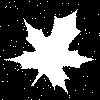

rayleigh_noise_15.png


100%|██████████| 200/200 [02:00<00:00,  1.65it/s]


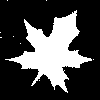

gaussian_noise_05.png


100%|██████████| 200/200 [02:03<00:00,  1.61it/s]


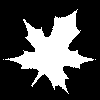

gaussian_noise_10.png


100%|██████████| 200/200 [01:59<00:00,  1.67it/s]


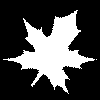

gaussian_noise_15.png


100%|██████████| 200/200 [02:00<00:00,  1.66it/s]


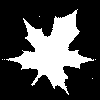

rayleigh_noise_05.png


100%|██████████| 200/200 [01:59<00:00,  1.67it/s]


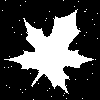

sp_noise_05.png


100%|██████████| 200/200 [01:59<00:00,  1.67it/s]


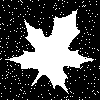

sp_noise_10.png


100%|██████████| 200/200 [01:56<00:00,  1.72it/s]


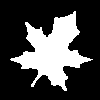

sp_noise_15.png


100%|██████████| 200/200 [01:56<00:00,  1.72it/s]


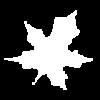

speckle_noise_05.png


100%|██████████| 200/200 [02:00<00:00,  1.66it/s]


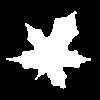

speckle_noise_10.png


100%|██████████| 200/200 [01:56<00:00,  1.72it/s]


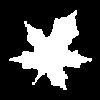

speckle_noise_15.png


100%|██████████| 200/200 [01:54<00:00,  1.74it/s]


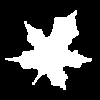

hasil_segmentasi


error: OpenCV(4.13.0) /io/opencv/modules/imgproc/src/resize.cpp:4208: error: (-215:Assertion failed) !ssize.empty() in function 'resize'


In [ ]:
#load data
T = 200
rate = 0.4
pisah = 'mean'
wjk = 1

for i in os.listdir('sintetis/'):
  print(i)
  filename = 'sintetis/'+i
  img = cv2.imread(filename,0)
  #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  img = cv2.resize(img, (100,100))
  #get data
  par_temp, delta_hasil = sintetis_Normal(img, T=T, rate=rate, pisah = pisah, wjk=wjk)
  cv2_imshow((delta_hasil+1)/2*255)
  cv2.imwrite('sintetis/hasil_segmentasi/new/'+'Normal_'+i, (delta_hasil+1)/2*255)

## No 4. Gaussian Mixture Model

In [ ]:
from sklearn.mixture import GaussianMixture
def GMM(img):
  y = img/255.
  P, Q = y.shape
  xjk = y.flatten().reshape(-1, 1)
  gm = GaussianMixture(n_components=2, random_state=0).fit(xjk)
  cv2_imshow(gm.predict(xjk).reshape(100,100)*255)
  return gm.predict(xjk).reshape(100,100)*255

rayleigh_noise_10.png


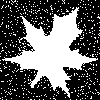

rayleigh_noise_15.png


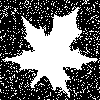

gaussian_noise_05.png


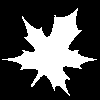

gaussian_noise_10.png


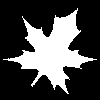

gaussian_noise_15.png


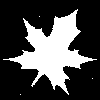

rayleigh_noise_05.png


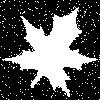

sp_noise_05.png


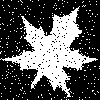

sp_noise_10.png


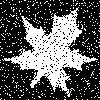

sp_noise_15.png


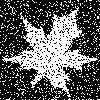

speckle_noise_05.png


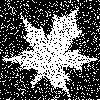

speckle_noise_10.png


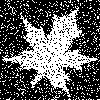

speckle_noise_15.png


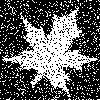

In [ ]:
#load data
for i in os.listdir('sintetis/')[:-1]:
  print(i)
  filename = 'sintetis/'+i
  img = cv2.imread(filename,0)
  #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  img = cv2.resize(img, (100,100))
  hasil = GMM(img)
  cv2.imwrite('sintetis/hasil_segmentasi/new/'+'GMM_'+i, hasil)

## No 5. Bayesian Gaussian Mixture

In [ ]:
from sklearn.mixture import BayesianGaussianMixture
def BGM(img):
  y = img/255.
  P, Q = y.shape
  xjk = y.flatten().reshape(-1, 1)
  bgm = BayesianGaussianMixture(n_components=2, random_state=0).fit(xjk)
  cv2_imshow(bgm.predict(xjk).reshape(100,100)*255)
  return bgm.predict(xjk).reshape(100,100)*255

rayleigh_noise_10.png


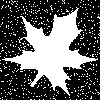

rayleigh_noise_15.png


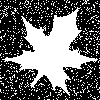

gaussian_noise_05.png


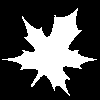

gaussian_noise_10.png


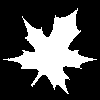

gaussian_noise_15.png


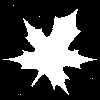

rayleigh_noise_05.png


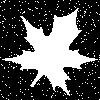

sp_noise_05.png


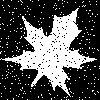

sp_noise_10.png


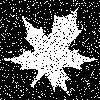

sp_noise_15.png


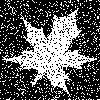

speckle_noise_05.png


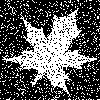

speckle_noise_10.png


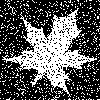

speckle_noise_15.png


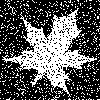

In [ ]:
#load data
for i in os.listdir('sintetis/')[:-1]:
  print(i)
  filename = 'sintetis/'+i
  img = cv2.imread(filename,0)
  #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  img = cv2.resize(img, (100,100))
  hasil = BGM(img)
  cv2.imwrite('sintetis/hasil_segmentasi/new/'+'BGM_'+i, hasil)

## No 6. MSNBurr Ising

In [ ]:
#be(alpha) =  ((1+1/alpha)**(alpha+1))/np.sqrt(2*np.pi)

# Distribusi MSNBurr
def beta(alpha):
    return ((1+1/alpha)**(alpha+1))/np.sqrt(2*np.pi)

def MSNBurr(xjk, mu, phi, alpha):
    x = xjk
    #be = beta(alpha)
    be = ((1+1/alpha)**(alpha+1))/np.sqrt(2*np.pi)
    kanan = np.exp(-1*be*((x-mu)/phi))
    hitung1 = (1+kanan/alpha)**(-1*(alpha+1))
    hitung2 = (be/phi)*kanan*hitung1
    return hitung2

# Neo Normal Ising Model
def NNIM(xjk, mu, phi, alpha, delta):
    mu_m1 = mu[0]
    mu_p1 = mu[1]
    phi_m1 = phi[0]
    phi_p1 = phi[1]
    alpha_m1 = alpha[0]
    alpha_p1 = alpha[1]
    NNIM = MSNBurr(xjk,mu_m1, phi_m1, alpha_m1)**((1-delta)/2)*MSNBurr(xjk,mu_p1, phi_p1, alpha_p1)**((1+delta)/2)
    return NNIM

def pdfnorm(mu, par):
    eta = par[0]; sigma = par[1]
    return 1/(sigma*np.sqrt(2*np.pi))*np.exp(-(1/2)*((mu-eta)/sigma)**2)

def pdfinvgamma(phi, par):
  psi = par[0]; xi = par[1]
  return (xi**psi)/gamma(psi)*phi**(-(psi+1))*np.exp(-xi/phi)


def pdfgsbeta(alpha, par):
  tau = par[0]; kappa = par[1]; u = par[2]
  return gamma(2*tau)/gamma(tau**2)*(((alpha-kappa)*(u-alpha))**(tau-1)/(u-kappa)**(2*tau-1))

# full conditional posterior
#def beta1():
# return 1/np.sqrt(2*np.pi*phi)

def fcposterior(x, par_FC):
  # input: x, (param, xjk, delta_t, par_t, par_p, min = True)
  param = par_FC[0]; xjk = par_FC[1]; delta_t = par_FC[2]; par_t = par_FC[3]; par_p = par_FC[4]; min = par_FC[5]

  #delta_t = delta_t.flatten()

  if min == True:
    mu = par_t[0][0]
    phi = par_t[1][0]
    alpha = par_t[2][0]
    d = 1
    #d = (1-delta_t.flatten())/2
  else:
    mu = par_t[0][1]
    phi = par_t[1][1]
    alpha = par_t[2][1]
    d = 1
    #d = (1+delta_t.flatten())/2

  if param == 'mu':
    mu = x
    eta = par_p[0]; sigma = par_p[1]

    be = beta(alpha)
    #be = 1/np.sqrt(2*np.pi)
    fcp = np.sum(d*(-1*be*(xjk-mu)/phi - (alpha+1)*np.log(1+np.exp(-be*(xjk-mu)/phi)/alpha))) -0.5*((mu-eta)/sigma)**2

    return fcp

  if param == 'phi':
    phi = x
    psi = par_p[0]; xi = par_p[1]

    be = beta(alpha)
    #be = 1/np.sqrt(2*np.pi)
    fcp = - (psi+1)*np.log(phi)  - xi/phi + np.sum(d*(np.log(be/phi)- be*(xjk-mu)/phi - (alpha+1)*np.log(1+np.exp(-1*be*(xjk-mu)/phi)/alpha)))
    return fcp

  if param == 'alpha':
    alpha = x
    #tau = par_p[0]; kappa = par_p[1]; u = par_p[2]
    tau = 2; kappa = 1; u = 2

    #be = beta1()
    be = beta(alpha)
    #be = 1/np.sqrt(2*np.pi)
    fcp =  (tau-1)*np.log((alpha-kappa)*(u-alpha)) + np.sum(d*((alpha+1)*np.log(1+(1/alpha)) - be*(xjk-mu)/phi - (alpha+1)*np.log(1+np.exp(-be*(xjk-mu)/phi)/alpha)))
    return fcp

def bangkitmu(m, par_p, par_FC):
  c = 10**6 #Correction AR
  # par_FC = x, param, xjk, delta_t, par_t, par_p, min = True
  #Acceptance Rejection
  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    #print(i)
    while accept == False:
      xrvs = np.random.normal(par_p[0],par_p[1],size=1)
      fx = fcposterior(xrvs, par_FC)
      Tx = np.log(stats.norm.pdf(xrvs, par_p[0], par_p[1]))
      ft = fx/(c*Tx)
      #ft = ft/10**4
      u = np.random.uniform(0, 1, size=1)
      #print(xrvs, fx, Tx, ft, np.log(u))
      if(np.log(u) <= ft):
        x_temp[i] = xrvs
        accept = True
  return np.mean(x_temp)

def bangkitphi(m, par_p, par_FC):
  c = 10**6 #Correction AR
  #Acceptance Rejection
  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    while accept == False:
      xrvs = stats.invgamma.rvs(par_p[0], scale=par_p[1], size = 1)[0]
      #xrvs = stats.gamma.rvs(par_p[0], scale=par_p[1], size = 1)
      fx = fcposterior(xrvs, par_FC)
      Tx = np.log(stats.invgamma.pdf(xrvs, par_p[0], scale=par_p[1]))
      ft = fx/(c*Tx)
      u = np.random.uniform(0, 1, size=1)
      #print(xrvs, fx, Tx, ft, np.log(u))
      if(np.log(u) <= ft):
        x_temp[i] = xrvs
        accept = True
  return np.mean(x_temp)

def bangkitalpha(m, par_p, par_FC):
  # par_FC = x, param, xjk, delta_t, par_t, par_p, min = True
  # Acceptance Rejection
  if par_FC[5] == True:
    s3 = 1
  else:
    s3 = 1

  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    #print(i)
    while accept == False:
      xrvs = stats.gamma.rvs(par_p[0], scale=par_p[1], size = 1)[0] + 1
      if (xrvs < 1) or (xrvs > 2):
        continue
      else:
        fx = fcposterior(xrvs, par_FC)
        Tx = np.log(pdfgsbeta(xrvs, [2,1,2]))
        ft = fx/(s3*Tx)
        u = np.random.uniform(0, 1, size=1)
        #print(xrvs, fx, Tx, ft, u)
        if(u <= ft):
          x_temp[i] = xrvs
          accept = True
  return np.mean(x_temp)

# rng distribution
def xrand(par_x):
  #input: (dist, par_p, size)
  dist = par_x[0]; par_p = par_x[1]; size = par_x[2]
  if dist == 'normal':
    return np.random.normal(par_p[0],par_p[1],size=size)[0]
  if dist == 'invgamma':
    return stats.invgamma.rvs(par_p[0], scale=par_p[1], size = size)[0]
  if dist == 'gamma':
    return stats.gamma.rvs(par_p[0], scale=par_p[1], size = size)[0]


In [ ]:
def sintetis_MSN(img, T, rate, pisah,wjk,dist = 'MSNBurr'):
  # Try
  y = img/255.
  #y = 2*y-1
  wjk = wjk #coupling strength (w_jk)
  P, Q = y.shape
  xjk = y.flatten()

  #plt.hist(xjk, bins=50)
  #plt.show()

  #y = xjk.reshape((Q,P))
  xjk.shape, y.shape

  # Inisialisasi
  # proses gibbs sampling
  # 1. inisialisasi parameter dari masing-masing prior pada t=0
  par_temp = np.empty((T+1,), dtype=np.ndarray) #teta_t
  #rate = 0.3 #smoothing update

  delta_t = None
  del delta_t
  delta_t = np.empty(xjk.shape)*(np.nan)
  if pisah == 'median':
    delta_t[np.where(xjk <= np.nanmedian(xjk))[0]] = -1
    delta_t[np.where(xjk > np.nanmedian(xjk))[0]] = 1
  if pisah == 'mode':
    delta_t[np.where(xjk <= mode(xjk))[0]] = -1
    delta_t[np.where(xjk > mode(xjk))[0]] = 1
  if pisah == 'mean':
    delta_t[np.where(xjk <= np.nanmean(xjk))[0]] = -1
    delta_t[np.where(xjk > np.nanmean(xjk))[0]] = 1

  xjk_m = xjk[np.where(delta_t == -1)]
  xjk_p = xjk[np.where(delta_t == 1)]

  delta_t = np.reshape(delta_t, (Q, P))
  mu_m1_t = np.mean(xjk_m)
  mu_p1_t = np.mean(xjk_p)

  phi_m1_t = np.std(xjk_m)
  phi_p1_t = np.std(xjk_p)

  alpha_m1_t = 1
  alpha_p1_t = 1

  par_t = [[mu_m1_t,mu_p1_t],[phi_m1_t,phi_p1_t],[alpha_m1_t,alpha_p1_t]]
  par_t = np.array(par_t)

  #print(len(xjk_m), len(xjk_p), np.mean(xjk_m), np.mean(xjk_p))
  par_temp[0] = par_t

  #rint('inisialisisasi done')
  #cv2_imshow((delta_t+1)/2*255)

  # 2. pembangkitan parameter ke-t (sistem acceptance rejection)
  m = 100 #number of sampler
  it = 0
  for t in tqdm(range(T)):
    it += 1
    z = delta_t
    # perbarui delta
    L_m = ((1-z.flatten())/2)*np.log(MSNBurr(xjk, mu_m1_t, phi_m1_t, alpha_m1_t))
    L_p = ((1+z.flatten())/2)*np.log(MSNBurr(xjk, mu_p1_t, phi_p1_t, alpha_p1_t))

    L_m = np.reshape(L_m, (Q,P))
    L_p = np.reshape(L_p, (Q,P))

    del delta_t, xjk_m, xjk_p
    delta_t = np.reshape(np.empty(xjk.shape)*(np.nan), (Q,P))
    for ij in range(P):
      for ik in range(Q):
        pos = ik + Q*ij
        neighborhood = pos + np.array([-1,1,-Q,Q])
        boundary_idx = [ik!=0,ik!=Q-1,ij!=0,ij!=P-1]
        neighborhood = neighborhood[np.where(boundary_idx)[0]]

        jj, kk = np.unravel_index(pos, (Q,P), order='F')
        nj, nk = np.unravel_index(neighborhood, (Q,P), order='F')

        Sbar = wjk*np.nansum(z[nj,nk])
        if np.isnan(z[jj,kk]):
          delta_t[jj,kk] = np.nan
        else:
          #z[jj,kk] = rate*z[jj,kk] + (1-rate)*np.tanh(Sbar+ 0.5*(L_p[jj,kk] - L_m[jj,kk])) #
          z[jj,kk] = rate*z[jj,kk] + (1-rate)*(1/(1+np.exp(-2*Sbar + L_m[jj,kk] - L_p[jj,kk])) - 1/(1+np.exp(2*Sbar - L_m[jj,kk] + L_p[jj,kk])))
          if z[jj,kk] < 0:
            delta_t[jj,kk] = -1
          else:
            delta_t[jj,kk] = 1

    xjk_m = xjk[np.where(delta_t.flatten() == -1)]
    xjk_p = xjk[np.where(delta_t.flatten() == 1)]

    delta_t = np.reshape(delta_t, (Q, P))
    #print(t, len(xjk_m), len(xjk_p), np.mean(xjk_m), np.mean(xjk_p))

    #cv2.imshow('Image'+str(it), (delta_t+1)/2*255)
    #cv2.waitKey()
    par_temp[it] = [np.empty(2)*(np.nan),np.empty(2)*(np.nan),np.empty(2)*(np.nan)]

    # bangkitkan mu
    par_t = [par_temp[it-1][0],par_temp[it-1][1],par_temp[it-1][2]]

    par_p = [np.mean(xjk_m),np.std(xjk_m)]
    par_FC = ('mu', xjk_m, delta_t, par_t, par_p, True)
    mu_m1_t = bangkitmu(m, par_p, par_FC)

    par_p = [np.mean(xjk_p),np.std(xjk_p)]
    par_FC = ('mu', xjk_p, delta_t, par_t, par_p, False)
    mu_p1_t = bangkitmu(m, par_p, par_FC)

    par_temp[it][0] = [mu_m1_t,mu_p1_t]
    #print(t,': mu done')

    #bangkitkan phi
    par_t = [par_temp[it][0],par_temp[it-1][1],par_temp[it-1][2]]

    par_p = [2, np.std(xjk_m)]
    par_FC = ('phi', xjk_m, delta_t, par_t, par_p, True)
    phi_m1_t =  bangkitphi(m, par_p, par_FC)

    par_p = [2, np.std(xjk_p)]
    par_FC = ('phi', xjk_p, delta_t, par_t, par_p, False)
    phi_p1_t =  bangkitphi(m, par_p, par_FC)

    par_temp[it][1] = [phi_m1_t,phi_p1_t]
    #print(t,': phi done')

    # bangkitkan alpha
    par_t = [par_temp[it][0],par_temp[it][1],par_temp[it-1][2]]
    par_p = [1, np.std(xjk_m)/np.sqrt(1)]
    par_FC = ('alpha', xjk_m, delta_t, par_t, par_p, True)
    alpha_m1_t =  bangkitalpha(m, par_p, par_FC)

    par_p = [1, np.std(xjk_p)/np.sqrt(1)]
    par_FC = ('alpha', xjk_p, delta_t, par_t, par_p, False)
    alpha_p1_t =  bangkitalpha(m, par_p, par_FC)

    par_temp[it][2] = [alpha_m1_t,alpha_p1_t]
    #print(t,': alpha done')

    #if t%50 == 0:
    #  cv2_imshow((delta_t+1)/2*255)
  return par_temp, delta_t

rayleigh_noise_10.png


100%|██████████| 200/200 [01:57<00:00,  1.70it/s]


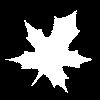

rayleigh_noise_15.png


100%|██████████| 200/200 [01:54<00:00,  1.74it/s]


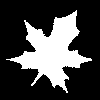

gaussian_noise_05.png


100%|██████████| 200/200 [01:54<00:00,  1.74it/s]


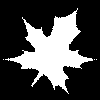

gaussian_noise_10.png


100%|██████████| 200/200 [01:54<00:00,  1.75it/s]


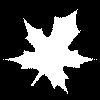

gaussian_noise_15.png


100%|██████████| 200/200 [01:54<00:00,  1.75it/s]


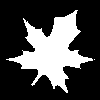

rayleigh_noise_05.png


100%|██████████| 200/200 [01:53<00:00,  1.76it/s]


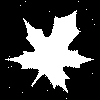

sp_noise_05.png


100%|██████████| 200/200 [01:54<00:00,  1.75it/s]


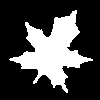

sp_noise_10.png


100%|██████████| 200/200 [01:59<00:00,  1.67it/s]


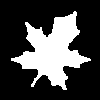

sp_noise_15.png


100%|██████████| 200/200 [01:55<00:00,  1.73it/s]


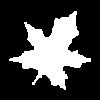

speckle_noise_05.png


100%|██████████| 200/200 [01:57<00:00,  1.70it/s]


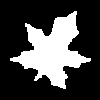

speckle_noise_10.png


100%|██████████| 200/200 [01:55<00:00,  1.73it/s]


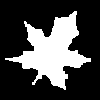

speckle_noise_15.png


100%|██████████| 200/200 [01:55<00:00,  1.73it/s]


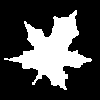

hasil_segmentasi


error: OpenCV(4.12.0) /io/opencv/modules/imgproc/src/resize.cpp:4208: error: (-215:Assertion failed) !ssize.empty() in function 'resize'


In [ ]:
#load data
T = 200
rate = 0.4
pisah = 'mean'
wjk = 1

for i in os.listdir('sintetis/'):
  print(i)
  filename = 'sintetis/'+i
  img = cv2.imread(filename,0)
  #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  img = cv2.resize(img, (100,100))
  #get data
  par_temp, delta_hasil = sintetis_MSN(img, T=T, rate=rate, pisah = pisah, wjk=wjk)
  cv2_imshow((delta_hasil+1)/2*255)
  cv2.imwrite('sintetis/hasil_segmentasi/'+'MSNBurr_'+i, (delta_hasil+1)/2*255)

## No 7. MSTBurr Ising

In [ ]:
#be(alpha) =  ((1+1/alpha)**(alpha+1))/np.sqrt(2*np.pi)
import math

# Distribusi MSTBurr
def beta(alpha, xjk):
    nl = len(xjk)
    hitung1 = gammastirling((nl+1)/2)*(1+1/alpha)**(alpha+1)
    hitung2 = gammastirling(nl/2)*np.sqrt(np.sqrt(nl)) #np.sqrt(nl)
    #h1 = gamma(nl)*(1+1/alpha)**(alpha+1)
    #h2 = np.sqrt(nl)*gamma(nl/2)
    #return h1/h2
    #return ((1+1/alpha)**(alpha+1))/np.sqrt(2*np.pi)
    return hitung1/hitung2

def MSTBurr(xjk, mu, phi, alpha):
    x = xjk
    be = beta(alpha,x)
    kanan = np.exp(-1*be*((x-mu)/phi))
    hitung1 = (1+kanan/alpha)**(-1*(alpha+1))
    hitung2 = (be/phi)*kanan*hitung1
    return hitung2

# Neo Normal Ising Model
def NNIM(xjk, mu, phi, alpha, delta):
    mu_m1 = mu[0]
    mu_p1 = mu[1]
    phi_m1 = phi[0]
    phi_p1 = phi[1]
    alpha_m1 = alpha[0]
    alpha_p1 = alpha[1]
    NNIM = MSTBurr(xjk,mu_m1, phi_m1, alpha_m1)**((1-delta)/2)*MSTBurr(xjk,mu_p1, phi_p1, alpha_p1)**((1+delta)/2)
    return NNIM

def pdfnorm(mu, par):
    eta = par[0]; sigma = par[1]
    return 1/(sigma*np.sqrt(2*np.pi))*np.exp(-(1/2)*((mu-eta)/sigma)**2)

def pdfinvgamma(phi, par):
  psi = par[0]; xi = par[1]
  return (xi**psi)/gamma(psi)*phi**(-(psi+1))*np.exp(-xi/phi)


def pdfgsbeta(alpha, par):
  tau = par[0]; kappa = par[1]; u = par[2]
  return gamma(2*tau)/gamma(tau**2)*(((alpha-kappa)*(u-alpha))**(tau-1)/(u-kappa)**(2*tau-1))

# full conditional posterior

def fcposterior(x, par_FC):
  # input: x, (param, xjk, delta_t, par_t, par_p, min = True)
  param = par_FC[0]; xjk = par_FC[1]; delta_t = par_FC[2]; par_t = par_FC[3]; par_p = par_FC[4]; min = par_FC[5]

  #delta_t = delta_t.flatten()

  if min == True:
    mu = par_t[0][0]
    phi = par_t[1][0]
    alpha = par_t[2][0]
    d = 1
    #d = (1-delta_t.flatten())/2
  else:
    mu = par_t[0][1]
    phi = par_t[1][1]
    alpha = par_t[2][1]
    d = 1
    #d = (1+delta_t.flatten())/2

  if param == 'mu':
    mu = x
    eta = par_p[0]; sigma = par_p[1]

    be = beta(alpha,xjk)
    fcp = np.sum(d*(-1*be*(xjk-mu)/phi - (alpha+1)*np.log(1+np.exp(-be*(xjk-mu)/phi)/alpha))) -0.5*((mu-eta)/sigma)**2

    return fcp

  if param == 'phi':
    phi = x
    psi = par_p[0]; xi = par_p[1]

    be = beta(alpha,xjk)
    #be = 1/np.sqrt(2*np.pi)
    fcp = - (psi+1)*np.log(phi)  - xi/phi + np.sum(d*(np.log(be/phi)- be*(xjk-mu)/phi - (alpha+1)*np.log(1+np.exp(-1*be*(xjk-mu)/phi)/alpha)))
    return fcp

  if param == 'alpha':
    alpha = x
    #tau = par_p[0]; kappa = par_p[1]; u = par_p[2]
    tau = 2; kappa = 1; u = 2

    be = beta(alpha,xjk)
    #be = 1/np.sqrt(2*np.pi)
    fcp =  (tau-1)*np.log((alpha-kappa)*(u-alpha)) + np.sum(d*((alpha+1)*np.log(1+(1/alpha)) - be*(xjk-mu)/phi - (alpha+1)*np.log(1+np.exp(-be*(xjk-mu)/phi)/alpha)))
    return fcp

def bangkitmu(m, par_p, par_FC):
  c = 10**6 #Correction AR
  # par_FC = x, param, xjk, delta_t, par_t, par_p, min = True
  #Acceptance Rejection
  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    #print(i)
    while accept == False:
      xrvs = np.random.normal(par_p[0],par_p[1],size=1)
      fx = fcposterior(xrvs, par_FC)
      Tx = np.log(stats.norm.pdf(xrvs, par_p[0], par_p[1]))
      ft = fx/(c*Tx)
      #ft = ft/10**4
      u = np.random.uniform(0, 1, size=1)
      #print(xrvs, fx, Tx, ft, np.log(u))
      if(np.log(u) <= ft):
        x_temp[i] = xrvs
        accept = True
  return np.mean(x_temp)

def bangkitphi(m, par_p, par_FC):
  c = 10**6 #Correction AR
  #Acceptance Rejection
  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    while accept == False:
      xrvs = stats.invgamma.rvs(par_p[0], scale=par_p[1], size = 1)[0]
      #xrvs = stats.gamma.rvs(par_p[0], scale=par_p[1], size = 1)
      fx = fcposterior(xrvs, par_FC)
      Tx = np.log(stats.invgamma.pdf(xrvs, par_p[0], scale=par_p[1]))
      ft = fx/(c*Tx)
      u = np.random.uniform(0, 1, size=1)
      #print(xrvs, fx, Tx, ft, np.log(u))
      if(np.log(u) <= ft):
        x_temp[i] = xrvs
        accept = True
  return np.mean(x_temp)

def bangkitalpha(m, par_p, par_FC):
  # par_FC = x, param, xjk, delta_t, par_t, par_p, min = True
  # Acceptance Rejection
  if par_FC[5] == True:
    s3 = 1
  else:
    s3 = 1

  x_temp = np.empty(m)*(np.nan)
  for i in range(m):
    accept = False
    #print(i)
    while accept == False:
      xrvs = stats.gamma.rvs(par_p[0], scale=par_p[1], size = 1)[0] + 1
      if (xrvs < 1) or (xrvs > 2):
        continue
      else:
        fx = fcposterior(xrvs, par_FC)
        Tx = np.log(pdfgsbeta(xrvs, [2,1,2]))
        ft = fx/(s3*Tx)
        u = np.random.uniform(0, 1, size=1)
        #print(xrvs, fx, Tx, ft, u)
        if(u <= ft):
          x_temp[i] = xrvs
          accept = True
  return np.mean(x_temp)

# rng distribution
def xrand(par_x):
  #input: (dist, par_p, size)
  dist = par_x[0]; par_p = par_x[1]; size = par_x[2]
  if dist == 'normal':
    return np.random.normal(par_p[0],par_p[1],size=size)[0]
  if dist == 'invgamma':
    return stats.invgamma.rvs(par_p[0], scale=par_p[1], size = size)[0]
  if dist == 'gamma':
    return stats.gamma.rvs(par_p[0], scale=par_p[1], size = size)[0]

def gammastirling(N):
  N = N-1
  return N * math.log2(N) - N + 0.5 * math.log2(2 * math.pi * N)


In [ ]:
def sintetis_MST(img, T, rate, pisah,wjk,dist = 'MSTBurr'):
  # Try
  y = img/255.
  #y = 2*y-1
  wjk = wjk #coupling strength (w_jk)
  P, Q = y.shape
  xjk = y.flatten()

  #plt.hist(xjk, bins=50)
  #plt.show()

  #y = xjk.reshape((Q,P))
  xjk.shape, y.shape

  nl = len(xjk)

  # Inisialisasi
  # proses gibbs sampling
  # 1. inisialisasi parameter dari masing-masing prior pada t=0
  par_temp = np.empty((T+1,), dtype=np.ndarray) #teta_t
  #rate = 0.3 #smoothing update

  delta_t = None
  del delta_t
  delta_t = np.empty(xjk.shape)*(np.nan)
  if pisah == 'median':
    delta_t[np.where(xjk <= np.nanmedian(xjk))[0]] = -1
    delta_t[np.where(xjk > np.nanmedian(xjk))[0]] = 1
  if pisah == 'mode':
    delta_t[np.where(xjk <= mode(xjk))[0]] = -1
    delta_t[np.where(xjk > mode(xjk))[0]] = 1
  if pisah == 'mean':
    delta_t[np.where(xjk <= np.nanmean(xjk))[0]] = -1
    delta_t[np.where(xjk > np.nanmean(xjk))[0]] = 1

  xjk_m = xjk[np.where(delta_t == -1)]
  xjk_p = xjk[np.where(delta_t == 1)]

  delta_t = np.reshape(delta_t, (Q, P))
  mu_m1_t = np.mean(xjk_m)
  mu_p1_t = np.mean(xjk_p)

  phi_m1_t = np.std(xjk_m)
  phi_p1_t = np.std(xjk_p)

  alpha_m1_t = 1
  alpha_p1_t = 1

  par_t = [[mu_m1_t,mu_p1_t],[phi_m1_t,phi_p1_t],[alpha_m1_t,alpha_p1_t]]
  par_t = np.array(par_t)

  #print(len(xjk_m), len(xjk_p), np.mean(xjk_m), np.mean(xjk_p))
  par_temp[0] = par_t

  #rint('inisialisisasi done')
  #cv2_imshow((delta_t+1)/2*255)

  # 2. pembangkitan parameter ke-t (sistem acceptance rejection)
  m = 100 #number of sampler
  it = 0
  for t in tqdm(range(T)):
    it += 1
    z = delta_t
    # perbarui delta
    L_m = ((1-z.flatten())/2)*np.log(MSTBurr(xjk, mu_m1_t, phi_m1_t, alpha_m1_t))
    L_p = ((1+z.flatten())/2)*np.log(MSTBurr(xjk, mu_p1_t, phi_p1_t, alpha_p1_t))

    L_m = np.reshape(L_m, (Q,P))
    L_p = np.reshape(L_p, (Q,P))

    del delta_t, xjk_m, xjk_p
    delta_t = np.reshape(np.empty(xjk.shape)*(np.nan), (Q,P))
    for ij in range(P):
      for ik in range(Q):
        pos = ik + Q*ij
        neighborhood = pos + np.array([-1,1,-Q,Q])
        boundary_idx = [ik!=0,ik!=Q-1,ij!=0,ij!=P-1]
        neighborhood = neighborhood[np.where(boundary_idx)[0]]

        jj, kk = np.unravel_index(pos, (Q,P), order='F')
        nj, nk = np.unravel_index(neighborhood, (Q,P), order='F')

        Sbar = wjk*np.nansum(z[nj,nk])
        if np.isnan(z[jj,kk]):
          delta_t[jj,kk] = np.nan
        else:
          #z[jj,kk] = rate*z[jj,kk] + (1-rate)*np.tanh(Sbar+ 0.5*(L_p[jj,kk] - L_m[jj,kk])) #
          z[jj,kk] = rate*z[jj,kk] + (1-rate)*(1/(1+np.exp(-2*Sbar + L_m[jj,kk] - L_p[jj,kk])) - 1/(1+np.exp(2*Sbar - L_m[jj,kk] + L_p[jj,kk])))
          if z[jj,kk] < 0:
            delta_t[jj,kk] = -1
          else:
            delta_t[jj,kk] = 1

    xjk_m = xjk[np.where(delta_t.flatten() == -1)]
    xjk_p = xjk[np.where(delta_t.flatten() == 1)]

    delta_t = np.reshape(delta_t, (Q, P))
    #print(t, len(xjk_m), len(xjk_p), np.mean(xjk_m), np.mean(xjk_p))

    #cv2.imshow('Image'+str(it), (delta_t+1)/2*255)
    #cv2.waitKey()
    par_temp[it] = [np.empty(2)*(np.nan),np.empty(2)*(np.nan),np.empty(2)*(np.nan)]

    # bangkitkan mu
    par_t = [par_temp[it-1][0],par_temp[it-1][1],par_temp[it-1][2]]

    par_p = [np.mean(xjk_m),np.std(xjk_m)]
    par_FC = ('mu', xjk_m, delta_t, par_t, par_p, True)
    mu_m1_t = bangkitmu(m, par_p, par_FC)

    par_p = [np.mean(xjk_p),np.std(xjk_p)]
    par_FC = ('mu', xjk_p, delta_t, par_t, par_p, False)
    mu_p1_t = bangkitmu(m, par_p, par_FC)

    par_temp[it][0] = [mu_m1_t,mu_p1_t]
    #print(t,': mu done')

    #bangkitkan phi
    par_t = [par_temp[it][0],par_temp[it-1][1],par_temp[it-1][2]]

    par_p = [2, np.std(xjk_m)]
    par_FC = ('phi', xjk_m, delta_t, par_t, par_p, True)
    phi_m1_t =  bangkitphi(m, par_p, par_FC)

    par_p = [2, np.std(xjk_p)]
    par_FC = ('phi', xjk_p, delta_t, par_t, par_p, False)
    phi_p1_t =  bangkitphi(m, par_p, par_FC)

    par_temp[it][1] = [phi_m1_t,phi_p1_t]
    #print(t,': phi done')

    # bangkitkan alpha
    par_t = [par_temp[it][0],par_temp[it][1],par_temp[it-1][2]]
    par_p = [1, np.std(xjk_m)/np.sqrt(1)]
    par_FC = ('alpha', xjk_m, delta_t, par_t, par_p, True)
    alpha_m1_t =  bangkitalpha(m, par_p, par_FC)

    par_p = [1, np.std(xjk_p)/np.sqrt(1)]
    par_FC = ('alpha', xjk_p, delta_t, par_t, par_p, False)
    alpha_p1_t =  bangkitalpha(m, par_p, par_FC)

    par_temp[it][2] = [alpha_m1_t,alpha_p1_t]
    #print(t,': alpha done')

    #if t%50 == 0:
    #  cv2_imshow((delta_t+1)/2*255)
  return par_temp, delta_t

In [ ]:
os.listdir('sintetis/')

['rayleigh_noise_10.png',
 'rayleigh_noise_15.png',
 'gaussian_noise_05.png',
 'gaussian_noise_10.png',
 'gaussian_noise_15.png',
 'rayleigh_noise_05.png',
 'sp_noise_05.png',
 'sp_noise_10.png',
 'sp_noise_15.png',
 'speckle_noise_05.png',
 'speckle_noise_10.png',
 'speckle_noise_15.png',
 'hasil_segmentasi']

rayleigh_noise_10.png


100%|██████████| 50/50 [00:31<00:00,  1.57it/s]


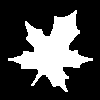

rayleigh_noise_15.png


100%|██████████| 50/50 [00:30<00:00,  1.65it/s]


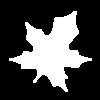

gaussian_noise_05.png


100%|██████████| 50/50 [00:29<00:00,  1.70it/s]


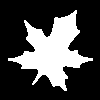

gaussian_noise_10.png


100%|██████████| 50/50 [00:29<00:00,  1.71it/s]


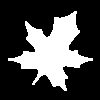

gaussian_noise_15.png


100%|██████████| 50/50 [00:29<00:00,  1.72it/s]


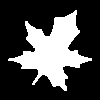

rayleigh_noise_05.png


100%|██████████| 50/50 [00:29<00:00,  1.69it/s]


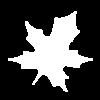

sp_noise_05.png


100%|██████████| 50/50 [00:30<00:00,  1.66it/s]


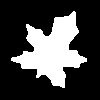

sp_noise_10.png


100%|██████████| 50/50 [00:29<00:00,  1.69it/s]


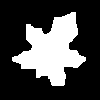

sp_noise_15.png


100%|██████████| 50/50 [00:29<00:00,  1.68it/s]


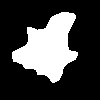

speckle_noise_05.png


100%|██████████| 50/50 [00:29<00:00,  1.71it/s]


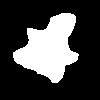

speckle_noise_10.png


100%|██████████| 50/50 [00:30<00:00,  1.66it/s]


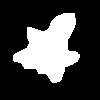

speckle_noise_15.png


100%|██████████| 50/50 [00:30<00:00,  1.66it/s]


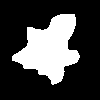

In [ ]:
#load data
T = 50
rate = 0.4
pisah = 'mean'
wjk = 1

for i in os.listdir('sintetis/')[:-1]:
  print(i)
  filename = 'sintetis/'+i
  img = cv2.imread(filename,0)
  #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  img = cv2.resize(img, (100,100))
  #get data
  par_temp, delta_hasil = sintetis_MST(img, T=T, rate=rate, pisah = pisah, wjk=wjk)
  cv2_imshow((delta_hasil+1)/2*255)
  cv2.imwrite('sintetis/hasil_segmentasi/'+'MSTBurr_'+i, (delta_hasil+1)/2*255)

# End

result:
https://docs.google.com/presentation/d/1740WxQ9o0ZmOli7_qnofX4UHyW24pl-OVKFIwQ5cOMk/edit?usp=sharing

# Kebaikan Model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir('/content/drive/MyDrive/data/')
os.getcwd()

import warnings
warnings.filterwarnings("ignore")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import cv2
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt
from sklearn import metrics

In [ ]:
def kebaikan_model(result, path_gt, resize):
  re_img = cv2.imread(result,0)
  re_img = cv2.resize(re_img, resize)
  re_img = np.where(re_img<112,0,1)
  #cv2_imshow(re_img*255)

  gt_img = cv2.imread(path_gt,0)
  gt_img = cv2.resize(gt_img, resize)
  gt_img = np.where(gt_img<112,0,1)
  #cv2_imshow(gt_img*255)

  actual = gt_img.flatten()
  predicted = re_img.flatten()
  confusion_matrix = metrics.confusion_matrix(actual, predicted)
  cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = ['bg', 'ROI'])
  #cm_display.plot()
  #plt.show()

  smat = confusion_matrix
  tp = smat[1][1]
  fp = smat[1][0]
  fn = smat[0][1]
  tn = smat[0][0]

  return tp/(tp+fp), tp/(tp+fn), tn/(fp+tn), np.sqrt((tp/(tp+fn))*(tn/(fp+tn))), tp/(tp+fp+fn)

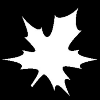

(100, 100)

In [ ]:
#load data
filename = 'Nguyen_1.png'

#get data
img = cv2.imread(filename,0)
#img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img = cv2.resize(img, (100,100))
cv2_imshow(img)
img.shape

In [ ]:
l = sorted(os.listdir('sintetis/hasil_segmentasi/new/'))

In [ ]:
df = pd.DataFrame(columns=['filename', 'prec', 'sens', 'spec', 'gmean', 'iou'])
for i in range(len(l)):
  df.loc[i] = [l[i]] + list(kebaikan_model('sintetis/hasil_segmentasi/new/'+l[i], 'Nguyen_1.png', (100,100)))
df

,filename,prec,sens,spec,gmean,iou
0,BGM_gaussian_noise_05.png,1.000000,0.973001,1.000000,0.986408,0.973001
1,BGM_gaussian_noise_10.png,0.995785,0.994737,0.998322,0.996528,0.990566
2,BGM_gaussian_noise_15.png,0.990868,0.992960,0.996368,0.994663,0.983955
3,BGM_rayleigh_noise_05.png,1.000000,0.848331,1.000000,0.921049,0.848331
4,BGM_rayleigh_noise_10.png,1.000000,0.767385,1.000000,0.876005,0.767385
...,...,...,...,...,...,...
79,SN_sp_noise_10.png,0.969793,0.991739,0.988082,0.989909,0.962021
80,SN_sp_noise_15.png,0.965227,0.976199,0.986221,0.981197,0.943034
81,SN_speckle_noise_05.png,0.959958,0.982034,0.984204,0.983118,0.943390
82,SN_speckle_noise_10.png,0.965227,0.979330,0.986239,0.982778,0.945955


In [ ]:
df.iloc[:12]

,filename,prec,sens,spec,gmean,iou
0,BGM_gaussian_noise_05.png,1.000000,0.973001,1.000000,0.986408,0.973001
1,BGM_gaussian_noise_10.png,0.995785,0.994737,0.998322,0.996528,0.990566
2,BGM_gaussian_noise_15.png,0.990868,0.992960,0.996368,0.994663,0.983955
3,BGM_rayleigh_noise_05.png,1.000000,0.848331,1.000000,0.921049,0.848331
4,BGM_rayleigh_noise_10.png,1.000000,0.767385,1.000000,0.876005,0.767385
5,BGM_rayleigh_noise_15.png,1.000000,0.696769,1.000000,0.834727,0.696769
6,BGM_sp_noise_05.png,0.948367,0.842697,0.978370,0.908003,0.805730
7,BGM_sp_noise_10.png,0.905163,0.755718,0.959029,0.851326,0.700272
8,BGM_sp_noise_15.png,0.844749,0.666205,0.930829,0.787479,0.593534
9,BGM_speckle_noise_05.png,0.844749,0.666020,0.930819,0.787365,0.593388


In [ ]:
df.iloc[60:71]

,filename,prec,sens,spec,gmean,iou
60,Normal_gaussian_noise_05.png,0.975413,0.996412,0.990295,0.993349,0.971999
61,Normal_gaussian_noise_10.png,0.982438,0.987990,0.993026,0.990505,0.970843
62,Normal_gaussian_noise_15.png,0.978223,0.990751,0.991376,0.991063,0.969370
63,Normal_rayleigh_noise_05.png,0.980681,0.974860,0.992293,0.983538,0.956492
64,Normal_rayleigh_noise_10.png,0.967685,0.960935,0.987102,0.973931,0.931058
65,Normal_rayleigh_noise_15.png,0.971549,0.992465,0.988770,0.990616,0.964435
66,Normal_sp_noise_05.png,0.968739,0.896036,0.987142,0.940487,0.870856
67,Normal_sp_noise_10.png,0.964173,0.992408,0.985900,0.989149,0.957113
68,Normal_sp_noise_15.png,0.965929,0.976562,0.986498,0.981518,0.944044
69,Normal_speckle_noise_05.png,0.933966,0.987008,0.974268,0.980617,0.922623


In [ ]:
df.to_csv('KebaikanModelPR3.csv')

# Numpy

In [ ]:
folder = '/content/drive/MyDrive/data/PR3/MSNBurr/'
l = sorted(os.listdir(folder))
l

['0.5_median_1_700.npy']

In [ ]:
z = np.load(folder+l[0])
z

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]])

In [ ]:
delta_t = np.zeros((z.shape[0], z.shape[1]))
for jj in range(z.shape[0]):
  for kk in range(z.shape[1]):
    if z[jj,kk] > 0:
      delta_t[jj,kk] = 1
    else:
      delta_t[jj,kk] = 0


In [ ]:
delta_t

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

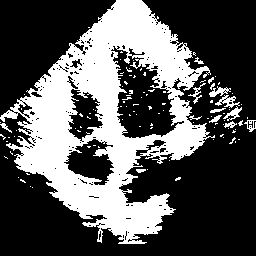

In [ ]:
cv2_imshow(delta_t*255)